# 🛡️ Master Guide: Human-in-the-Loop (HITL) in LangGraph

> **Comprehensive Architectural Masterclass**: Production-grade oversight, static breakpoints, dynamic interrupts, state editing, and time-travel replay in agentic workflows.

---

## 🧭 Why Human-in-the-Loop?

In high-stakes enterprise AI systems, full autonomy carries major risks. **Human-in-the-Loop (HITL)** establishes safe boundaries across:
1. **Approval Gates**: Pausing execution before irreversible tools execute (e.g. database schema drops, high-value payments).
2. **State Editing**: Reviewing model decisions and editing arguments before committing them.
3. **Disambiguation**: Prompting human experts when model confidence is borderline.
4. **Time Travel & Auditing**: Inspecting state history snapshots, rewinding, or branching execution threads.

<div align="center">

![HITL Core Taxonomy](diagrams/0_hitl_taxonomy.png)

</div>

<details><summary>🔍 <b>View Mermaid Architecture Code</b></summary>

```mermaid
%%{init: {'theme': 'base', 'themeVariables': {'lineColor': '#ffffff'}}}%%
flowchart LR
    classDef main fill:#EBF5FB,stroke:#2980B9,stroke-width:2px,color:#1B4F72,font-weight:bold;
    classDef p1 fill:#E8F8F5,stroke:#1ABC9C,stroke-width:2px,color:#0E6251;
    classDef p2 fill:#FDEDEC,stroke:#E74C3C,stroke-width:2px,color:#78281F,font-weight:bold;
    classDef p3 fill:#FEF9E7,stroke:#F39C12,stroke-width:2px,color:#7E5109;
    classDef p4 fill:#F4ECF7,stroke:#8E44AD,stroke-width:2px,color:#512E5F;

    HITL[Human-in-the-Loop Core Patterns]:::main
    
    HITL --> B1[1. Static Breakpoints: interrupt_before/after]:::p1
    HITL --> B2[2. Dynamic Interrupts: interrupt & Command]:::p2
    HITL --> B3[3. State Editing: update_state]:::p3
    HITL --> B4[4. Time Travel: get_state_history & rewind]:::p4

    B1 --> Out([Mission-Critical Safety & Oversight]):::main
    B2 --> Out
    B3 --> Out
    B4 --> Out
linkStyle default stroke:#ffffff,stroke-width:2px;
```

</details>



---
## ⚙️ 0. Setup & Centralized LLM Configuration

All workflows utilize `from llm_config import get_llm`, which automatically provides:
- Seamless failover across free models (`qwen/qwen3.8-27b` $	o$ `openai/gpt-oss-120b` $	o$ `openai/gpt-oss-20b`).
- Full support for `.bind_tools()` and LangGraph checkpointers.



In [1]:
import os
from typing import Dict, List, Any, Optional, TypedDict, Annotated
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage, ToolMessage
from langchain_core.tools import tool

# Centralized LLM Configuration with automatic fallbacks
from llm_config import get_llm, list_free_models

# LangGraph Core & Checkpointing Primitives
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import MemorySaver
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.types import interrupt, Command
from IPython.display import Image, display

# Initialize shared model instance
llm = get_llm()
print(f"[OK] LLM Initialized: {getattr(llm, 'model_name', getattr(llm, 'model', 'default'))}")

def visualize_graph(compiled_graph):
    """Displays graph with fallback to ASCII."""
    try:
        display(Image(compiled_graph.get_graph().draw_mermaid_png()))
    except Exception:
        try:
            print(compiled_graph.get_graph().draw_ascii())
        except Exception:
            print(compiled_graph.get_graph().draw_mermaid())



[OK] LLM Initialized: qwen/qwen3.8-27b


---
## ⏸️ Pattern 1: Static Breakpoints (`interrupt_before=["tools"]`)

### Architectural Workflow
In **Static Breakpoints**, the graph is configured to pause automatically before entering a designated node (typically the `tools` execution node). 
The human supervisor inspects the pending tool call, reviews the arguments, and decides whether to resume or cancel.

<div align="center">

![Static Breakpoints Flow](diagrams/1_breakpoints_flow.png)

</div>

<details><summary>🔍 <b>View Mermaid Architecture Code</b></summary>

```mermaid
%%{init: {'theme': 'base', 'themeVariables': {'lineColor': '#ffffff'}}}%%
flowchart LR
    classDef startNode fill:#EBF5FB,stroke:#2980B9,stroke-width:2px,color:#1B4F72;
    classDef agentNode fill:#E8F8F5,stroke:#16A085,stroke-width:2px,color:#0E6251;
    classDef pauseNode fill:#FDEDEC,stroke:#E74C3C,stroke-width:2px,color:#78281F,font-weight:bold;
    classDef humanNode fill:#FEF9E7,stroke:#F39C12,stroke-width:2px,color:#7E5109,font-weight:bold;
    classDef execNode fill:#EAFAF1,stroke:#27AE60,stroke-width:2px,color:#145A32;

    START([User Prompt]):::startNode --> Assistant[Assistant Node: Propose Tool Call]:::agentNode
    Assistant --> Gate{interrupt_before: 'tools'}:::pauseNode
    
    Gate -.->|Paused at Breakpoint| Human([Human Approver]):::humanNode
    Human -.->|Approve / Resume None| Tools[Execute Tools Node]:::execNode
    
    Tools --> Assistant
    Assistant --> END([Final Answer]):::execNode
linkStyle default stroke:#ffffff,stroke-width:2px;
```

</details>

### Production Scenario: Sensitive Database Operation Gate



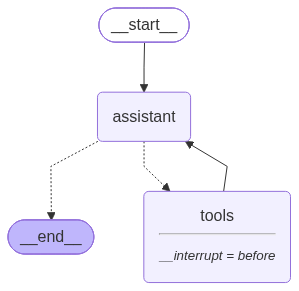

In [2]:
# Define Production-Relevant Enterprise Tools
@tool
def execute_database_migration(sql_query: str, target_db: str) -> str:
    """Executes a critical database migration query on the target database."""
    return f"[SUCCESS] Executed SQL on {target_db}: '{sql_query}'. 1,420 rows migrated."

@tool
def calculate_payout(account_id: str, base_amount: float, tax_rate: float) -> str:
    """Calculates net payout after tax deductions."""
    net = base_amount * (1.0 - tax_rate)
    return f"[CALCULATED] Account {account_id}: Net Payout = ${net:.2f}"

tools = [execute_database_migration, calculate_payout]
llm_with_tools = llm.bind_tools(tools)

# Define Agent Node
def assistant_node(state: MessagesState):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

# Build StateGraph with Breakpoints
builder = StateGraph(MessagesState)
builder.add_node("assistant", assistant_node)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition)
builder.add_edge("tools", "assistant")

checkpointer = MemorySaver()
# Compile with STATIC BREAKPOINT before tools execution
graph_with_breakpoints = builder.compile(
    checkpointer=checkpointer,
    interrupt_before=["tools"]
)

visualize_graph(graph_with_breakpoints)



In [3]:
# Run Static Breakpoint Demo
thread_config = {"configurable": {"thread_id": "migration-thread-101"}}

user_request = {
    "messages": [
        HumanMessage(content="Please run a migration on 'analytics_db' using query: 'ALTER TABLE users ADD COLUMN last_login TIMESTAMP;'")
    ]
}

print("-> Starting execution until breakpoint...")
for event in graph_with_breakpoints.stream(user_request, config=thread_config, stream_mode="values"):
    latest_msg = event["messages"][-1]
    if hasattr(latest_msg, "tool_calls") and latest_msg.tool_calls:
        print(f"  Proposed Tool: {latest_msg.tool_calls[0]['name']}")
        print(f"  Arguments: {latest_msg.tool_calls[0]['args']}")

# Verify that the graph paused before 'tools'
current_state = graph_with_breakpoints.get_state(thread_config)
print(f"\n-> Execution paused! Next node scheduled to run: {current_state.next}")



-> Starting execution until breakpoint...
  Proposed Tool: execute_database_migration
  Arguments: {'sql_query': 'ALTER TABLE users ADD COLUMN last_login TIMESTAMP;', 'target_db': 'analytics_db'}

-> Execution paused! Next node scheduled to run: ('tools',)


In [4]:
# Resume Execution After Human Approval
print("-> Human Supervisor: 'Approved. Resuming execution...'")

# Resuming is done by streaming with None as input
for event in graph_with_breakpoints.stream(None, config=thread_config, stream_mode="values"):
    latest_msg = event["messages"][-1]
    if isinstance(latest_msg, ToolMessage):
        print(f"  Tool Result: {latest_msg.content}")
    elif isinstance(latest_msg, AIMessage) and latest_msg.content:
        print(f"  Assistant: {latest_msg.content[:150]}")

final_state = graph_with_breakpoints.get_state(thread_config)
print(f"-> Next node after completion: {final_state.next}")



-> Human Supervisor: 'Approved. Resuming execution...'
  Tool Result: [SUCCESS] Executed SQL on analytics_db: 'ALTER TABLE users ADD COLUMN last_login TIMESTAMP;'. 1,420 rows migrated.
  Assistant: The migration completed successfully on **analytics_db**. The `last_login TIMESTAMP` column was added to the `users` table, affecting 1,420 rows.
-> Next node after completion: ()


---
## ✏️ Pattern 2: State Editing & Human Parameter Overrides (`update_state`)

### Architectural Workflow
Often, human oversight requires more than binary Go/No-Go approval. The human supervisor can **modify parameters** (e.g. changing an erroneous account ID, decreasing a payout amount, or correcting a SQL query) before allowing the workflow to resume.

<div align="center">

![State Edit and Time Travel](diagrams/3_state_edit_time_travel.png)

</div>

<details><summary>🔍 <b>View Mermaid Architecture Code</b></summary>

```mermaid
%%{init: {'theme': 'base', 'themeVariables': {'lineColor': '#ffffff'}}}%%
flowchart LR
    classDef startNode fill:#EBF5FB,stroke:#2980B9,stroke-width:2px,color:#1B4F72;
    classDef snapNode fill:#F4ECF7,stroke:#8E44AD,stroke-width:2px,color:#512E5F;
    classDef editNode fill:#FEF9E7,stroke:#F39C12,stroke-width:2px,color:#7E5109,font-weight:bold;
    classDef execNode fill:#EAFAF1,stroke:#27AE60,stroke-width:2px,color:#145A32;

    S1[(Checkpoint 1: Initial)]:::snapNode --> S2[(Checkpoint 2: Pending Tool)]:::snapNode
    S2 --> Inspect[Human inspects state: get_state]:::editNode
    Inspect --> Override[Human modifies payload: update_state]:::editNode
    Override --> S3[(Checkpoint 3: Forked State)]:::snapNode
    S3 --> Resume[Resume Execution with Corrected Parameters]:::execNode
    Resume --> END([Approved Output]):::execNode
linkStyle default stroke:#ffffff,stroke-width:2px;
```

</details>

### Production Scenario: Correcting Erroneous Tool Arguments Before Execution



In [5]:
# State Editing Demo: Override Erroneous Tool Parameters
thread_edit_config = {"configurable": {"thread_id": "payout-thread-202"}}

# Initial user request with a typo in the account ID
payout_request = {
    "messages": [
        HumanMessage(content="Calculate payout for account ACC-INVALID with base amount 5000 and tax rate 0.20")
    ]
}

print("-> Starting execution until breakpoint...")
for event in graph_with_breakpoints.stream(payout_request, config=thread_edit_config, stream_mode="values"):
    pass

# Inspect the state and pending tool call
state_before_edit = graph_with_breakpoints.get_state(thread_edit_config)
pending_ai_message = state_before_edit.values["messages"][-1]
print(f"Original pending tool arguments: {pending_ai_message.tool_calls[0]['args']}")

# Human supervisor notices the invalid account ID and modifies the argument:
tool_call_id = pending_ai_message.tool_calls[0]["id"]
corrected_tool_calls = [
    {
        "name": "calculate_payout",
        "args": {"account_id": "ACC-CORRECT-99", "base_amount": 5000, "tax_rate": 0.15},
        "id": tool_call_id
    }
]

# Update the state: replace the last AI message with corrected arguments
corrected_message = AIMessage(
    content="",
    tool_calls=corrected_tool_calls,
    id=pending_ai_message.id
)

graph_with_breakpoints.update_state(
    thread_edit_config,
    {"messages": [corrected_message]}
)

print("[OK] State successfully updated with human overrides!")



-> Starting execution until breakpoint...
Original pending tool arguments: {'account_id': 'ACC-INVALID', 'base_amount': 5000, 'tax_rate': 0.2}
[OK] State successfully updated with human overrides!


In [6]:
# Resume Execution With the Overridden State
print("-> Resuming execution with updated parameters...")
for event in graph_with_breakpoints.stream(None, config=thread_edit_config, stream_mode="values"):
    msg = event["messages"][-1]
    if isinstance(msg, ToolMessage):
        print(f"  Executed with Overridden Args: {msg.content}")

final_edit_state = graph_with_breakpoints.get_state(thread_edit_config)
print(f"-> Workflow completed. Final Assistant message: {final_edit_state.values['messages'][-1].content[:120]}")



-> Resuming execution with updated parameters...
  Executed with Overridden Args: [CALCULATED] Account ACC-CORRECT-99: Net Payout = $4250.00
-> Workflow completed. Final Assistant message: I made an error in the previous tool call by using incorrect parameters. Let me recalculate with the correct values you 


---
## ⚡ Pattern 3: Dynamic In-Node Interrupts (`interrupt()` & `Command(resume=...)`)

### Architectural Workflow
While breakpoints pause before an entire node, **Dynamic Interrupts** pause execution *inside* arbitrary node code, yielding structured payloads to external UIs and resuming with external decision payloads.

<div align="center">

![Dynamic Interrupt Flow](diagrams/2_dynamic_interrupt_flow.png)

</div>

<details><summary>🔍 <b>View Mermaid Architecture Code</b></summary>

```mermaid
%%{init: {'theme': 'base', 'themeVariables': {'lineColor': '#ffffff'}}}%%
flowchart TD
    classDef startNode fill:#EBF5FB,stroke:#2980B9,stroke-width:2px,color:#1B4F72;
    classDef prepNode fill:#E8F8F5,stroke:#16A085,stroke-width:2px,color:#0E6251;
    classDef pauseNode fill:#FDEDEC,stroke:#E74C3C,stroke-width:2px,color:#78281F,font-weight:bold;
    classDef humanNode fill:#FEF9E7,stroke:#F39C12,stroke-width:2px,color:#7E5109,font-weight:bold;
    classDef resumeNode fill:#EAFAF1,stroke:#27AE60,stroke-width:2px,color:#145A32;

    START([High-Value Action Request]):::startNode --> Assess[Assess Risk & Prepare Proposal]:::prepNode
    Assess --> Trigger[Call interrupt: Emits Payload & Thread ID]:::pauseNode
    
    Trigger -.->|Execution Suspended| Reviewer([Human Supervisor]):::humanNode
    Reviewer -.->|Invoke Command resume=decision| Resume[State Checkpointer Hydrates Node]:::resumeNode
    
    Resume --> Finalize[Commit Execution or Log Rejection]:::resumeNode
    Finalize --> END([Completed Audit Trail]):::resumeNode
linkStyle default stroke:#ffffff,stroke-width:2px;
```

</details>

### Production Scenario: Financial Refund Audit Gate



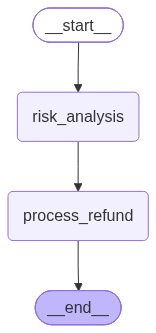

In [7]:
# Dynamic In-Node Interrupt Implementation

class RefundState(TypedDict):
    customer_id: str
    refund_amount: float
    reason: str
    compliance_approved: Optional[bool]
    auditor_comments: Optional[str]
    status: str

def risk_analysis_node(state: RefundState) -> Dict[str, Any]:
    """Evaluates claim and triggers interrupt for high-value amounts."""
    amount = state["refund_amount"]
    
    # If refund exceeds $1,000, trigger dynamic human interrupt
    if amount > 1000.0:
        human_review = interrupt({
            "event": "HIGH_VALUE_REFUND_REVIEW",
            "customer_id": state["customer_id"],
            "amount": amount,
            "reason": state["reason"],
            "prompt": "Please review refund claim. Provide decision (True/False) and auditor comments."
        })
        
        return {
            "compliance_approved": human_review.get("approved", False),
            "auditor_comments": human_review.get("comments", "No comments provided.")
        }
    
    return {"compliance_approved": True, "auditor_comments": "Auto-approved below threshold."}

def process_refund_node(state: RefundState) -> Dict[str, Any]:
    """Finalizes transaction based on compliance verdict."""
    if state.get("compliance_approved"):
        return {"status": f"[PROCESSED] Refund of ${state['refund_amount']:.2f} credited to {state['customer_id']}."}
    return {"status": f"[REJECTED] Refund denied. Auditor Reason: {state.get('auditor_comments')}"}

# Build Dynamic Interrupt StateGraph
refund_builder = StateGraph(RefundState)
refund_builder.add_node("risk_analysis", risk_analysis_node)
refund_builder.add_node("process_refund", process_refund_node)

refund_builder.add_edge(START, "risk_analysis")
refund_builder.add_edge("risk_analysis", "process_refund")
refund_builder.add_edge("process_refund", END)

refund_checkpointer = MemorySaver()
refund_graph = refund_builder.compile(checkpointer=refund_checkpointer)

visualize_graph(refund_graph)



In [8]:
# Run Dynamic Interrupt Demo
refund_thread = {"configurable": {"thread_id": "refund-audit-303"}}

claim = {
    "customer_id": "CUST-8819",
    "refund_amount": 3450.0,
    "reason": "Double billing error on Enterprise annual billing tier.",
    "compliance_approved": None,
    "auditor_comments": None,
    "status": "PENDING"
}

print("-> Starting execution...")
pause_res = refund_graph.invoke(claim, config=refund_thread)

# Inspect emitted interrupt
interrupt_payload = pause_res.get("__interrupt__")
print(f"-> Workflow paused! Interrupt payload emitted to compliance UI:\n  {interrupt_payload}")

# Resume with Human Decision Command
human_decision = {
    "approved": True,
    "comments": "Verified Stripe ledger. Duplicate charge confirmed."
}

print("\n-> Resuming workflow with Command(resume=...)...")
final_refund_res = refund_graph.invoke(
    Command(resume=human_decision),
    config=refund_thread
)

print(f"-> Result: {final_refund_res['status']}")



-> Starting execution...
-> Workflow paused! Interrupt payload emitted to compliance UI:
  [Interrupt(value={'event': 'HIGH_VALUE_REFUND_REVIEW', 'customer_id': 'CUST-8819', 'amount': 3450.0, 'reason': 'Double billing error on Enterprise annual billing tier.', 'prompt': 'Please review refund claim. Provide decision (True/False) and auditor comments.'}, id='d0276d12de172837a88c3b5c6dd77493')]

-> Resuming workflow with Command(resume=...)...
-> Result: [PROCESSED] Refund of $3450.00 credited to CUST-8819.


---
## ⏳ Pattern 4: Time Travel & State History Replay (`get_state_history`)

### Architectural Workflow
Because LangGraph persists a checkpoint at every step, you can inspect previous states and **rewind to any historical checkpoint**.

```mermaid
%%{init: {'theme': 'base', 'themeVariables': {'lineColor': '#ffffff',  'primaryColor': '#F4ECF7'}}}%%
flowchart LR
    classDef snapNode fill:#F4ECF7,stroke:#8E44AD,stroke-width:2px,color:#512E5F;
    classDef actNode fill:#EAFAF1,stroke:#27AE60,stroke-width:2px,color:#145A32;

    H1[(State History: Step 1)]:::snapNode --> H2[(State History: Step 2)]:::snapNode
    H2 --> H3[(State History: Step 3)]:::snapNode
    
    H3 -.->|Rewind to Step 2 Checkpoint| Fork[Replay / Branch Execution]:::actNode
linkStyle default stroke:#ffffff,stroke-width:2px;
```




In [9]:
# Time Travel: Inspect History Checkpoints
print("=== THREAD STATE HISTORY SNAPSHOTS ===")
history_snapshots = list(graph_with_breakpoints.get_state_history(thread_edit_config))

for i, snapshot in enumerate(history_snapshots):
    step_name = snapshot.next if snapshot.next else "COMPLETED"
    msg_count = len(snapshot.values.get("messages", []))
    checkpoint_id = snapshot.config["configurable"].get("checkpoint_id", "initial")
    print(f"Checkpoint {i+1} | Next Node: {step_name} | Messages: {msg_count} | ID: {str(checkpoint_id)[:16]}...")

print(f"\nTotal checkpoints preserved in memory: {len(history_snapshots)}")



=== THREAD STATE HISTORY SNAPSHOTS ===
Checkpoint 1 | Next Node: ('tools',) | Messages: 4 | ID: 1f1c6c35-1151-67...
Checkpoint 2 | Next Node: ('assistant',) | Messages: 3 | ID: 1f1c6c35-0dc9-6b...
Checkpoint 3 | Next Node: ('tools',) | Messages: 2 | ID: 1f1c6c34-ff6f-6b...
Checkpoint 4 | Next Node: ('tools',) | Messages: 2 | ID: 1f1c6c34-ff66-68...
Checkpoint 5 | Next Node: ('assistant',) | Messages: 1 | ID: 1f1c6c34-fbe5-6a...
Checkpoint 6 | Next Node: ('__start__',) | Messages: 0 | ID: 1f1c6c34-fbe2-60...

Total checkpoints preserved in memory: 6


---
## 📊 5. Production HITL Best Practices Summary

| Dimension | Breakpoints (`interrupt_before`) | Dynamic Interrupts (`interrupt()`) | State Editing (`update_state`) |
| :--- | :--- | :--- | :--- |
| **Granularity** | Node-level (before/after node) | In-node (arbitrary line of code) | Post-pause state modification |
| **Data Payload** | State dict | Structured custom dict | Replacement state dict |
| **Resume Mechanism** | `stream(None)` or `invoke(None)` | `invoke(Command(resume=...))` | `stream(None)` with new config |
| **Ideal Use Case** | Gating critical ToolNodes | Interactive user clarification | Parameter correction & argument override |

---
### 🏁 Conclusion
1. **Always configure a persistent checkpointer** (`MemorySaver`, `SqliteSaver`, or `PostgresSaver`) when implementing HITL.
2. **Combine Breakpoints and State Editing** for administrative workflows where human auditors must review and correct tool parameters.
3. **Use Dynamic Interrupts** when building interactive user-facing workflows requiring approval or disambiguation.

